# Function 3 — Week 9 full-cohort exploration

The 23 November snapshot contains 23 official observations and 28 published peer returns. 3 peer returns are new since 12 November.

[Model comparison](model_predictions.ipynb) · [Cohort review and next-query table](../../../../results/week-09-cohort-review.md)

In [1]:
%matplotlib inline
from pathlib import Path
import hashlib
import json
import sys

from IPython.display import display
import numpy as np
import pandas as pd

ANALYSIS_DIR = Path.cwd().resolve()
ROOT = next(path for path in ANALYSIS_DIR.parents if (path / "run-python.ps1").is_file())
EXPECTED_KERNEL = ROOT / ".venv" / ("Scripts/python.exe" if sys.platform == "win32" else "bin/python")
if Path(sys.executable).resolve() != EXPECTED_KERNEL.resolve():
    raise RuntimeError(f"Select the Capstone kernel: {EXPECTED_KERNEL}")
STAGE = ROOT / "stage-2-bbo"
SHARED = STAGE / "notebooks/Shared"
if str(SHARED) not in sys.path:
    sys.path.insert(0, str(SHARED))
from cohort_review_helpers import load_dated_cohort_review


In [2]:
FUNCTION_NUMBER = 3
INPUT_COLUMNS = ['x1', 'x2', 'x3']
EXPECTED_ROUND_COUNTS = {0: 15, 1: 1, 2: 1, 3: 1, 4: 1, 5: 1, 6: 1, 7: 1, 8: 1}

In [3]:
OFFICIAL_DIR = ANALYSIS_DIR.parent / "official" if FUNCTION_NUMBER <= 4 else ANALYSIS_DIR.parent
OFFICIAL_CSV = OFFICIAL_DIR / "observations.csv"
SNAPSHOT = STAGE / "data/cohort/2026-11-23"
FIGURES = ANALYSIS_DIR / "figures"
FIGURES.mkdir(exist_ok=True)
review, intake = load_dated_cohort_review(SNAPSHOT, OFFICIAL_CSV, function=FUNCTION_NUMBER,
    input_columns=INPUT_COLUMNS, expected_round_counts=EXPECTED_ROUND_COUNTS)
official_data = review["own_data"]
peer_data = review["data"].loc[review["peer_mask"]]
display(pd.Series({"Official observations": len(official_data), "Published peer returns": len(peer_data),
    "New peer returns since 12 November": intake["new_peer"], "Total observations": len(review["data"])}))


Official observations                 23
Published peer returns                28
New peer returns since 12 November     3
Total observations                    51
dtype: int64

## Measured scores

The close-up shows the five highest scores. The latest marker follows the official record. Peer round labels are local to each reporting repository.

Round 8 return                     -0.004952
Rank among official observations    1.000000
Rank in the full snapshot           2.000000
Best official score                -0.004952
Best published peer score          -0.000140
dtype: float64

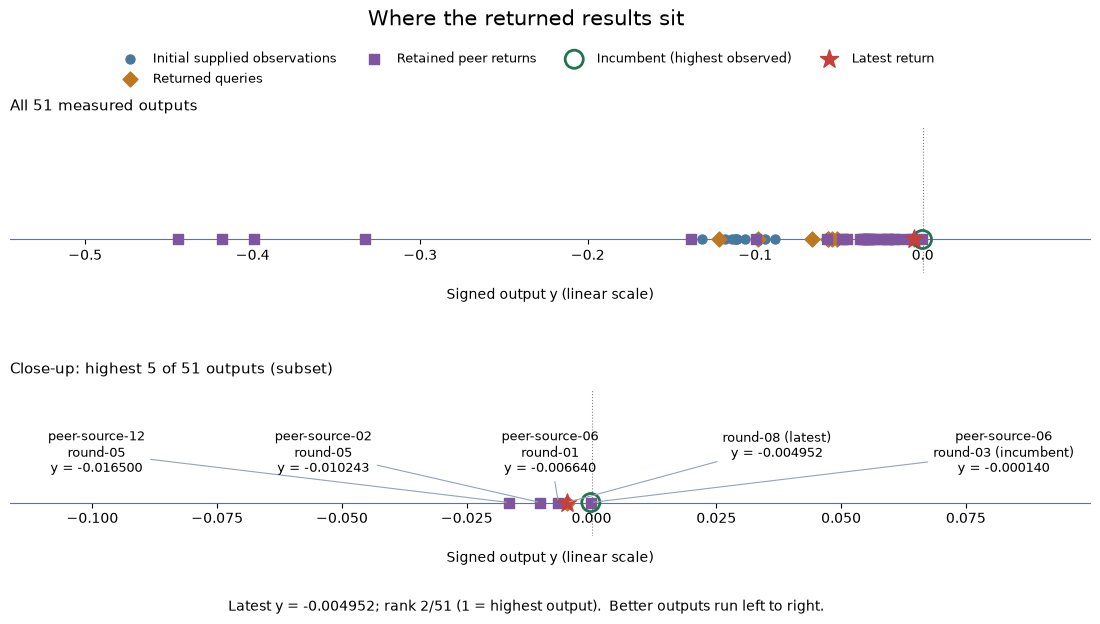

In [4]:
from observation_review_helpers import (
    prepare_weekly_observation_review, plot_output_review, plot_round_progress, plot_input_profiles,
)

prepared = prepare_weekly_observation_review(review, history=official_data)
latest = prepared["latest"]
latest_official_rank = int((official_data.y > latest.y).sum()) + 1
latest_cohort_rank = int((review["data"].y > latest.y).sum()) + 1
display(pd.Series({"Round 8 return": latest.y, "Rank among official observations": latest_official_rank,
    "Rank in the full snapshot": latest_cohort_rank, "Best official score": official_data.y.max(),
    "Best published peer score": peer_data.y.max()}))
display(plot_output_review(review, save_to=FIGURES / "observed-output-review.png"))


## Official progress

The running maximum follows the eight official returns.

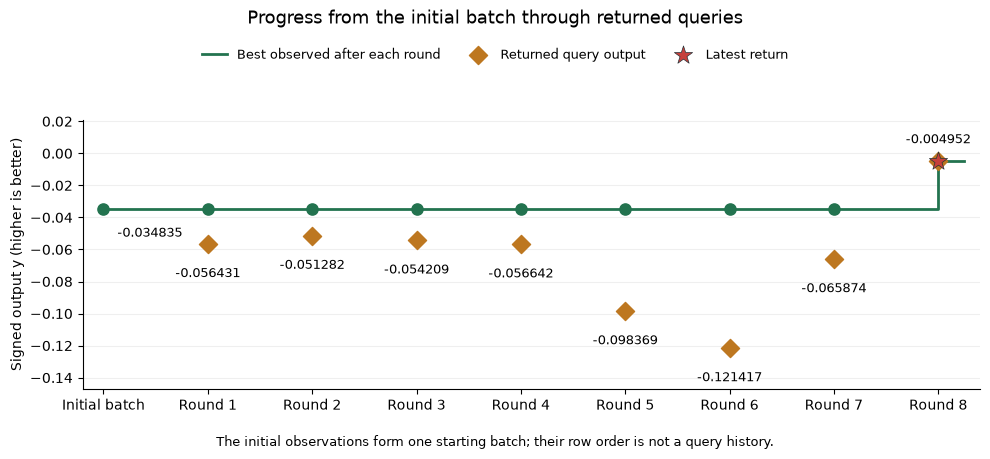

,returned_y,best_y,change_vs_prior_best
stage,,,
Initial batch,NaN,-0.034835,NaN
Round 1,-0.056431,-0.034835,-0.021596
Round 2,-0.051282,-0.034835,-0.016447
Round 3,-0.054209,-0.034835,-0.019373
Round 4,-0.056642,-0.034835,-0.021807
Round 5,-0.098369,-0.034835,-0.063534
Round 6,-0.121417,-0.034835,-0.086581
Round 7,-0.065874,-0.034835,-0.031039
Round 8,-0.004952,-0.004952,0.029883


In [5]:
display(plot_round_progress(prepared["progress"], save_to=FIGURES / "official-progress.png"))
display(prepared["progress"].set_index("stage")[["returned_y", "best_y", "change_vs_prior_best"]])


## Strongest measured input profiles

Colour encodes input settings on a common 0–1 scale.

,rank,observation_id,x1,x2,x3,y
37,1,peer-source-06-round-03,0.5200,0.550000,0.450000,-0.000140
22,2,round-08,0.5200,0.610000,0.450000,-0.004952
35,3,peer-source-06-round-01,0.4500,0.550000,0.450000,-0.006640
48,4,peer-source-02-round-05,0.4255,0.527545,0.422063,-0.010243
43,5,peer-source-12-round-05,0.8500,0.700000,0.384000,-0.016500


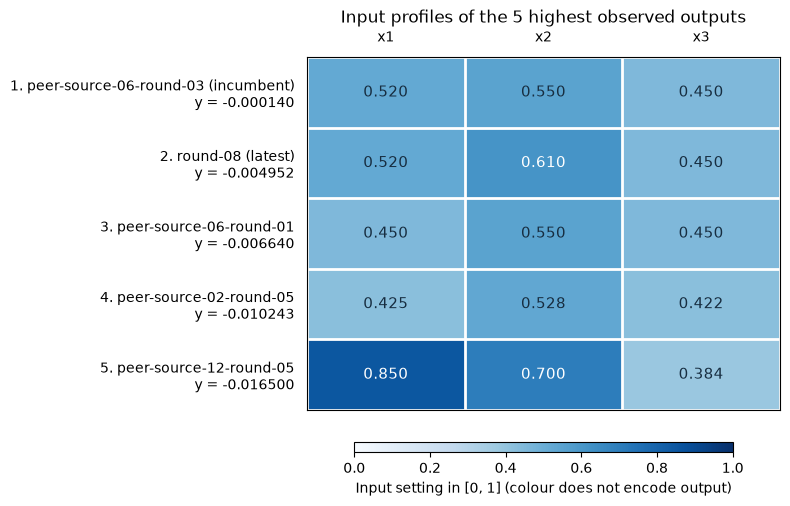

In [6]:
display(prepared["strongest"][["rank", "observation_id", *INPUT_COLUMNS, "y"]])
display(plot_input_profiles(prepared["strongest"], input_columns=INPUT_COLUMNS,
    latest_id=latest.observation_id, incumbent_id=prepared["incumbent"].observation_id,
    save_to=FIGURES / "strongest-input-profiles.png"))


In [7]:
summary = dict(function=FUNCTION_NUMBER, intake_date="2026-11-23",
    official_rows=intake["official"], peer_rows=intake["peer"], new_peer_rows=intake["new_peer"],
    latest_output=float(latest.y), latest_official_rank=latest_official_rank,
    latest_cohort_rank=latest_cohort_rank, official_best=float(official_data.y.max()),
    peer_best=float(peer_data.y.max()), best_peer_point=intake["peer_best_point"],
    official_snapshot_sha256=intake["official_sha256"], pooled_snapshot_sha256=intake["sha256"])
text = json.dumps(summary, indent=2, allow_nan=False)
(ANALYSIS_DIR / "observation-review.json").write_text(text + "\n", encoding="utf-8")
print(text)


{
  "function": 3,
  "intake_date": "2026-11-23",
  "official_rows": 23,
  "peer_rows": 28,
  "new_peer_rows": 3,
  "latest_output": -0.004952000821836788,
  "latest_official_rank": 1,
  "latest_cohort_rank": 2,
  "official_best": -0.004952000821836788,
  "peer_best": -0.0001403067678185869,
  "best_peer_point": [
    0.52,
    0.55,
    0.45
  ],
  "official_snapshot_sha256": "d54f514f8dfd111391561cbbcc842b7726d274be6895091d51434675c181a94b",
  "pooled_snapshot_sha256": "16dd67bf664614fb1d0243aacebb7b72a1454330cfb5b500485356abfb6f1c22"
}


## Preprocessing and validation diagnostics

Compare the middle half of each coordinate distribution and the empirical score distributions for official and published peer observations. Repeated groups use the rounded portal input across all coordinates. A peer at the same portal point as an official hold-out is withheld during validation. The model study tests median aggregation of training repeats and a higher assumed peer noise level. [Modelling experiments](model_predictions.ipynb#extended-cohort-surrogate-study)

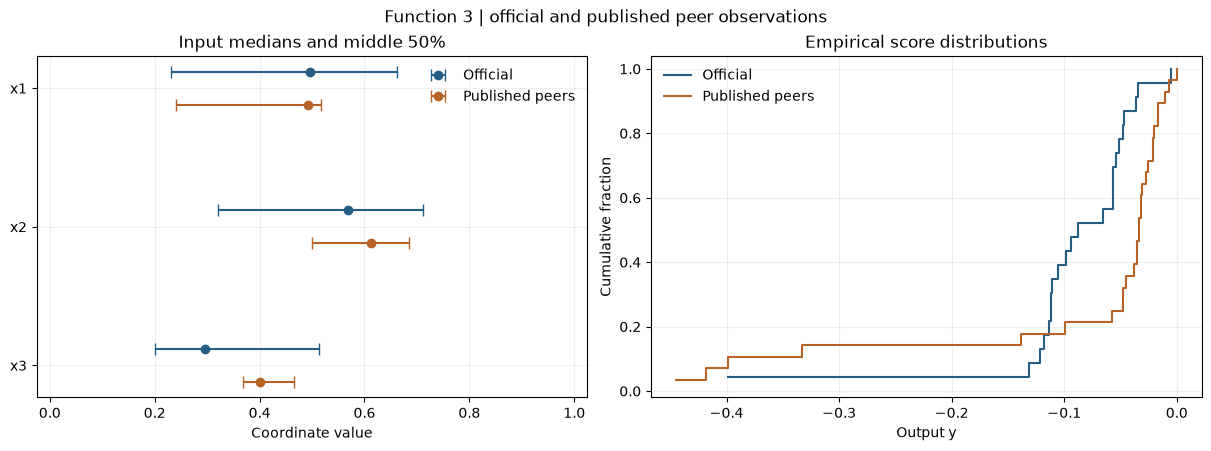

,scope,rows,rows_on_portal_boundary,score_median
0,Official,23,0,-0.087963
1,Published peers,28,1,-0.033339


portal_input_groups                 50.000000
repeated_input_groups                1.000000
peer_rows_matching_official          1.000000
median_peer_to_official_distance     0.112245
dtype: float64

In [8]:
from cohort_surrogate_plots import cohort_data_diagnostics

official_scores = official_data.y.to_numpy(dtype=float)
peer_scores = peer_data.y.to_numpy(dtype=float)
label = "Output y"
if FUNCTION_NUMBER == 1:
    function_helpers = STAGE / "notebooks/Function_1/FunctionSpecificShared"
    if str(function_helpers) not in sys.path:
        sys.path.insert(0, str(function_helpers))
    from function_1_model_helpers import signed_log
    official_scores = signed_log(official_scores, scale=1e-200)
    peer_scores = signed_log(peer_scores, scale=1e-200)
    label = "Signed-log height h"
diagnostics, distribution = cohort_data_diagnostics(review, official_scores, peer_scores,
    title=f"Function {FUNCTION_NUMBER} | official and published peer observations",
    target_label=label, save_to=FIGURES / "cohort-data-diagnostics.png")
display(distribution)
display(pd.DataFrame(diagnostics["by_scope"]))
display(pd.Series({key: value for key, value in diagnostics.items() if key != "by_scope"}))


### What the diagnostics show

The pooled data contain one repeated portal input in 51 observations. Published peer scores have a higher median (−0.033 versus −0.088). The median-aggregation experiment changes the training weight of the one repeat group.
